<a href="https://colab.research.google.com/github/Sharonsellnorbert/DSA_B13_casestudy/blob/main/Supervised_Learning_Assessment_Sharon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:
import pandas as pd

In [41]:
df=pd.read_csv('/content/drive/MyDrive/DSA/Datasets/bank_marketing_assessment_dataset.csv')

In [4]:
# First few records
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [6]:
df.describe()

,customer_age,account_balance,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate
count,600.000000,588.000000,600.000000,600.000000,600.000000,600.0000
mean,38.208333,1535.037415,5.566667,1.015000,4.451667,31805.3650
std,15.387426,2366.916896,2.020485,1.582914,2.938603,17264.0821
min,18.000000,-5418.000000,3.000000,0.000000,1.000000,12000.0000
25%,26.000000,-24.750000,4.000000,0.000000,1.000000,16112.5000
50%,34.000000,1589.500000,5.000000,0.000000,4.000000,29156.0000
75%,49.000000,3042.750000,7.000000,2.000000,7.000000,43444.0000
max,75.000000,9365.000000,13.000000,8.000000,10.000000,108930.0000


In [7]:
# Different datatypes
df.dtypes

,0
customer_age,int64
job,object
marital_status,object
education,object
account_balance,float64
housing_loan,object
personal_loan,object
contact_type,object
contact_month,object
campaign_contacts,int64


In [8]:
# Column Names
df.columns

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')

In [15]:
# Finding Shape
df.shape

(600, 14)

In [11]:
# finding missing values
df.isnull().sum()

,0
customer_age,0
job,0
marital_status,0
education,15
account_balance,12
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [17]:
# checking for duplicate rows
df.duplicated().sum()

np.int64(0)

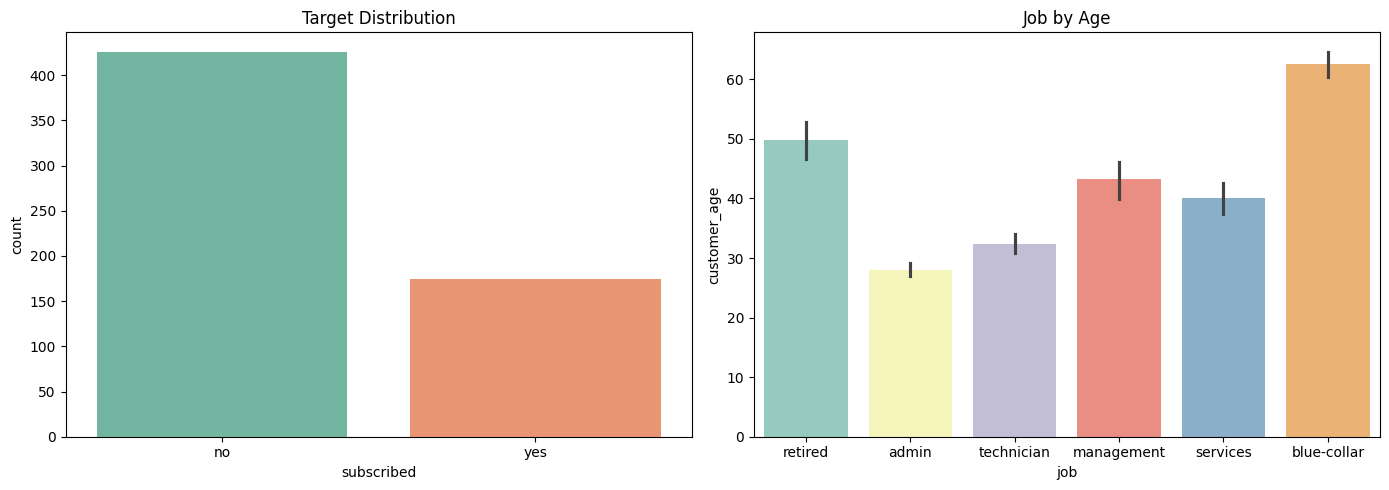

In [69]:
# Simpler, warning-free setup
plt.figure(figsize=(14, 5))

# 1. Target distribution
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='subscribed', hue='subscribed', palette='Set2', legend=False)
plt.title('Target Distribution')

# 2. Age distribution by job
plt.subplot(1, 2, 2)
sns.barplot(data=df, x='job', y='customer_age', hue='job', palette='Set3', legend=False)
plt.title('Job by Age')

plt.tight_layout()
plt.show()

### Target-Class Distribution and Key Observations

In [31]:
# 1. Target-Class Distribution Calculation
target_counts = df['subscribed'].value_counts()
target_pct = df['subscribed'].value_counts(normalize=True) * 100

print("--- Target-Class Distribution ('subscribed') ---")
for idx in target_counts.index:
    print(f"{idx.capitalize()}: {target_counts[idx]} ({target_pct[idx]:.2f}%)")
print("\n")

# Observation 1: Let's check the subscription rate across different job roles
job_subscription = df.groupby('job')['subscribed'].value_counts(normalize=True).unstack().fillna(0) * 100
print("--- Subscription Rate by Job (%) ---")
display(job_subscription.round(2))
print("\n")

# Observation 2: Check engagement score distribution between subscribers and non-subscribers
print("--- Mean Engagement Score and Balance by Subscription Status ---")
display(df.groupby('subscribed')[['engagement_score', 'account_balance', 'customer_age']].mean().round(2))

--- Target-Class Distribution ('subscribed') ---
No: 426 (71.00%)
Yes: 174 (29.00%)


--- Subscription Rate by Job (%) ---


subscribed,no,yes
job,,
admin,71.55,28.45
blue-collar,64.63,35.37
management,80.95,19.05
retired,65.91,34.09
services,72.37,27.63
technician,69.90,30.10




--- Mean Engagement Score and Balance by Subscription Status ---


,engagement_score,account_balance,customer_age
subscribed,,,
no,4.38,1543.81,37.44
yes,4.64,1513.64,40.10


### 2. Data preparation and feature engineering

In [47]:
# Separate input features and target
X = df.drop(columns=['subscribed'])
y = df['subscribed']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (600, 13)
Target shape: (600,)


In [48]:
from sklearn.model_selection import train_test_split

# Split with stratification and a fixed random state
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (480, 13)
Testing set shape: (120, 13)


In [49]:
# Handling Missing values and Encoding
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Identify column types
numerical_cols = ['customer_age', 'account_balance', 'campaign_contacts', 'previous_contacts', 'engagement_score', 'annual_income_estimate']
categorical_cols = ['job', 'marital_status', 'education', 'housing_loan', 'personal_loan', 'contact_type', 'contact_month']

# Create pipelines
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # Impute missing values (e.g., account_balance)
    ('scaler', StandardScaler())                    # Standardize features
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Impute missing values (e.g., education, contact_type)
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) # One-hot encode
])

# Bundle preprocessing into a ColumnTransformer
preprocessor_pipeline = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Fit ONLY on the training data and transform both to avoid data leakage
X_train_clean = preprocessor_pipeline.fit_transform(X_train)
X_test_clean = preprocessor_pipeline.transform(X_test)

# Retrieve column names for output reconstruction
cat_encoder_step = preprocessor_pipeline.named_transformers_['cat'].named_steps['encoder']
encoded_cat_names = cat_encoder_step.get_feature_names_out(categorical_cols)
processed_columns = numerical_cols + list(encoded_cat_names)

# Convert to DataFrames
X_train_clean_df = pd.DataFrame(X_train_clean, columns=processed_columns, index=X_train.index)
X_test_clean_df = pd.DataFrame(X_test_clean, columns=processed_columns, index=X_test.index)

display(X_train_clean_df.head())

,customer_age,account_balance,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,job_admin,job_blue-collar,job_management,job_retired,...,personal_loan_yes,contact_type_cellular,contact_type_telephone,contact_type_unknown,contact_month_aug,contact_month_jul,contact_month_jun,contact_month_may,contact_month_nov,contact_month_oct
443,2.376943,-1.824878,0.224138,-0.639364,1.908265,1.465516,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
189,-0.473283,-1.448990,-0.273946,-0.639364,-1.189708,-1.137055,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
384,-0.538061,0.925014,-0.772030,-0.639364,-0.157050,-0.893424,1.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
442,0.627940,-0.916413,-0.273946,-0.639364,-0.845489,-0.129219,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
563,-0.926728,1.233749,-0.772030,-0.639364,1.219827,2.201371,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [62]:
# Building a Logistic Regression Classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
lr=LogisticRegression(random_state=42)
lr.fit(X_train_clean, y_train)
y_pred = lr.predict(X_test_clean)







In [61]:
# Building a Decision Tree or random forest Classification model and display
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
dt=DecisionTreeClassifier(random_state=42)
dt.fit(X_train_clean, y_train)
y_pred = dt.predict(X_test_clean)





In [60]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# 1. Build reproducible Pipeline for Logistic Regression
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_pipeline),
    ('classifier', LogisticRegression(random_state=42))
])

# Fit the entire pipeline on the raw training data
lr_pipeline.fit(X_train, y_train)

# 2. Build reproducible Pipeline for Decision Tree
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_pipeline),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Fit the entire pipeline on the raw training data
dt_pipeline.fit(X_train, y_train)

print("Both pipelines have been successfully built, trained, and are reproducible!")

Both pipelines have been successfully built, trained, and are reproducible!


In [58]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

# Get predictions for both models on test set
y_pred_lr = lr.predict(X_test_clean)
y_pred_dt = dt.predict(X_test_clean)

# Calculate metrics
metrics_data = {
    'Logistic Regression': [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr, pos_label='yes'),
        recall_score(y_test, y_pred_lr, pos_label='yes'),
        f1_score(y_test, y_pred_lr, pos_label='yes')
    ],
    'Decision Tree': [
        accuracy_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt, pos_label='yes'),
        recall_score(y_test, y_pred_dt, pos_label='yes'),
        f1_score(y_test, y_pred_dt, pos_label='yes')
    ]
}

metrics_df = pd.DataFrame(metrics_data, index=['Accuracy', 'Precision (Subscribed)', 'Recall (Subscribed)', 'F1-Score (Subscribed)'])
display(metrics_df.round(4))

,Logistic Regression,Decision Tree
Accuracy,0.8500,0.8333
Precision (Subscribed),0.8696,0.7143
Recall (Subscribed),0.5714,0.7143
F1-Score (Subscribed),0.6897,0.7143


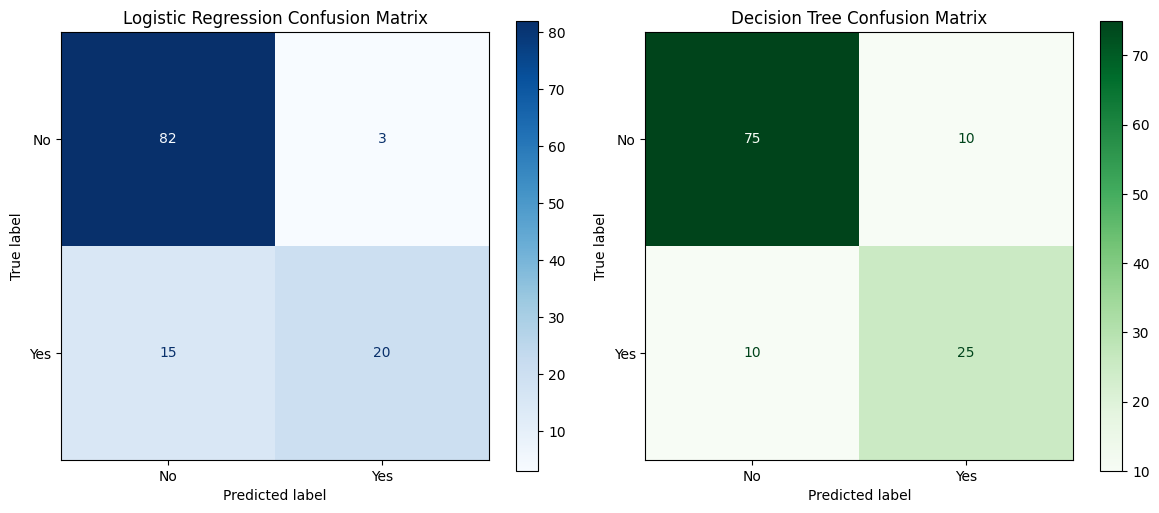

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix for Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=['no', 'yes'])
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['No', 'Yes'])
disp_lr.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Logistic Regression Confusion Matrix')

# Confusion Matrix for Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=['no', 'yes'])
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['No', 'Yes'])
disp_dt.plot(ax=axes[1], cmap='Greens', values_format='d')
axes[1].set_title('Decision Tree Confusion Matrix')

plt.tight_layout()
plt.show()

I recommend the **Decision Tree model** over Logistic Regression.

*  Although Logistic Regression is slightly more accurate overall ($85.00\%$ vs. $83.33\%$), the Decision Tree successfully identifies significantly more actual subscribers ($71.43\%$ Recall vs. $57.14\%$).
*  To boost performance further, we would next try a **Random Forest classifier** with tuned class weights to catch even more subscribers with fewer false alarms.

In [73]:
# identifying the most influential features using suitable model interpretation also showing limitations of the interpretation.

from sklearn.inspection import permutation_importance
importances = permutation_importance(dt, X_test_clean, y_test, n_repeats=10, random_state=42)
print("Feature importances:")
for feature, importance in zip(X_train_clean_df.columns, importances.importances_mean):
    print(f"{feature}: {importance}")

# Most important feature from using the model
print("\nMost Important Feature:")
most_important_feature = X_train_clean_df.columns[importances.importances_mean.argmax()]
print(most_important_feature)



# using the selected model to predict subsciption for five sample customers from the test set.Display the predicted class and if available ,probability
sample_customers = X_test_clean[:5]
predicted_classes = dt.predict(sample_customers)
predicted_probabilities = dt.predict_proba(sample_customers)
print("\nPredicted Classes:")
print(predicted_classes)
print("\nPredicted Probabilities:")
print(predicted_probabilities)



Feature importances:
customer_age: 0.05750000000000004
account_balance: -0.03083333333333328
campaign_contacts: 0.0025000000000000243
previous_contacts: 0.06333333333333337
engagement_score: 0.051666666666666694
annual_income_estimate: 0.05000000000000006
job_admin: 0.004166666666666707
job_blue-collar: 0.01666666666666672
job_management: 0.0
job_retired: 0.0
job_services: 0.0
job_technician: 0.001666666666666683
marital_status_divorced: 0.0
marital_status_married: 0.0008333333333333636
marital_status_single: 0.0
education_primary: 0.004166666666666707
education_secondary: 0.0
education_tertiary: 0.0
housing_loan_no: 0.011666666666666704
housing_loan_yes: 0.0
personal_loan_no: 0.135
personal_loan_yes: 0.0
contact_type_cellular: 0.00750000000000004
contact_type_telephone: 0.001666666666666683
contact_type_unknown: 0.0008333333333333859
contact_month_aug: -0.008333333333333304
contact_month_jul: 0.01916666666666672
contact_month_jun: 0.0
contact_month_may: 0.0
contact_month_nov: 0.007500

<!-- To Summmarize the reason for my model choice  -->
